##Import Required Libraries

In [1]:
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import re
import string
import joblib
import os
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import seaborn as sns

##Data Loading & Exploration

In [25]:
df = pd.read_csv('/content/GrievanceAI_Industry_Grade_5000.csv')
print(f"\nDataset loaded: {len(df)} samples")


Dataset loaded: 5000 samples


In [37]:
df.head()

,grievance_no,startup_name,grievance_text,category
0,G00001,LegalBridge,Need guidance preparing financial projections ...,Funding
1,G00002,NanoSoft,Angel investors are requesting traction metric...,Funding
2,G00003,BizFusion,Venture capital firms are not responding to ou...,Funding
3,G00004,EduWave,Difficulty closing a pre-seed round due to mar...,Funding
4,G00005,CloudForge,Investors are concerned about our revenue mode...,Funding


In [26]:
df.isnull().sum()

,0
grievance_no,0
startup_name,0
grievance_text,0
category,0


In [28]:
df.duplicated().sum()

np.int64(0)

In [29]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   grievance_no    5000 non-null   object
 1   startup_name    5000 non-null   object
 2   grievance_text  5000 non-null   object
 3   category        5000 non-null   object
dtypes: object(4)
memory usage: 156.4+ KB


In [30]:
df.dtypes

,0
grievance_no,object
startup_name,object
grievance_text,object
category,object


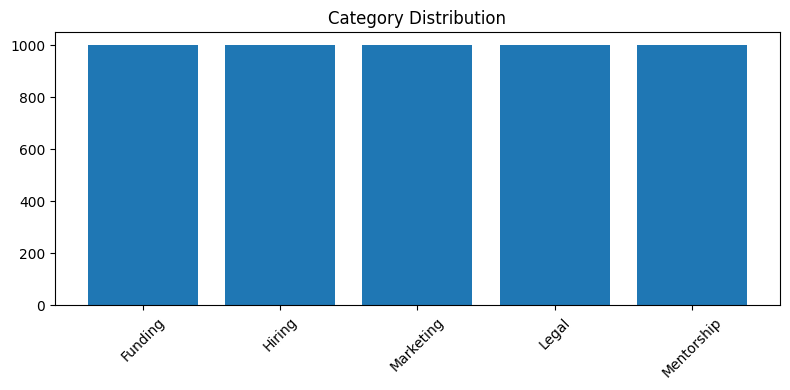

In [32]:
plt.figure(figsize=(8,4))

counts = df['category'].value_counts()
plt.bar(counts.index, counts.values)

plt.title("Category Distribution")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

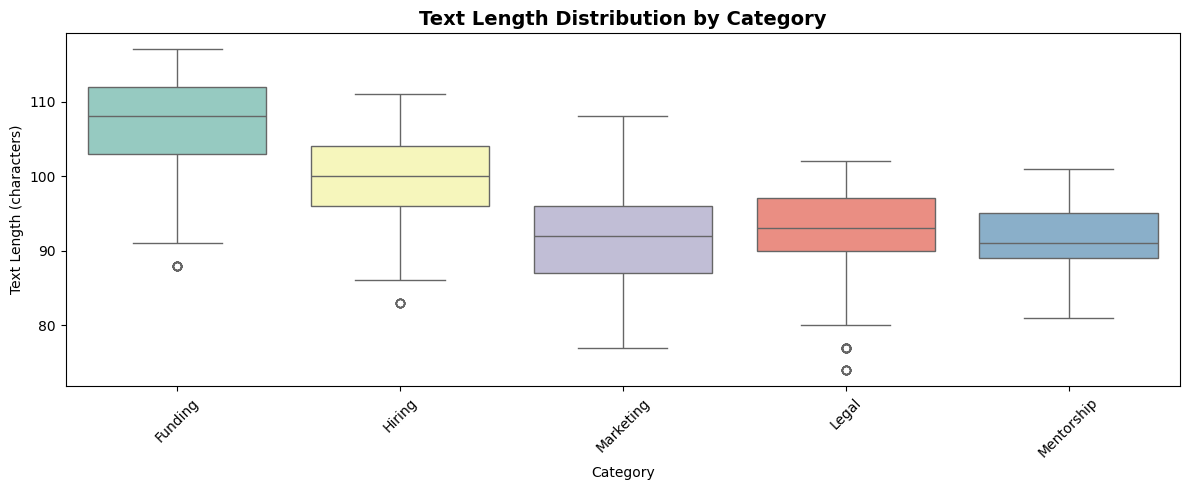

In [38]:
df['text_length'] = df['grievance_text'].str.len()
plt.figure(figsize=(12, 5))
sns.boxplot(x='category', y='text_length', data=df, palette='Set3')
plt.title('Text Length Distribution by Category', fontsize=14, fontweight='bold')
plt.xlabel('Category')
plt.ylabel('Text Length (characters)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

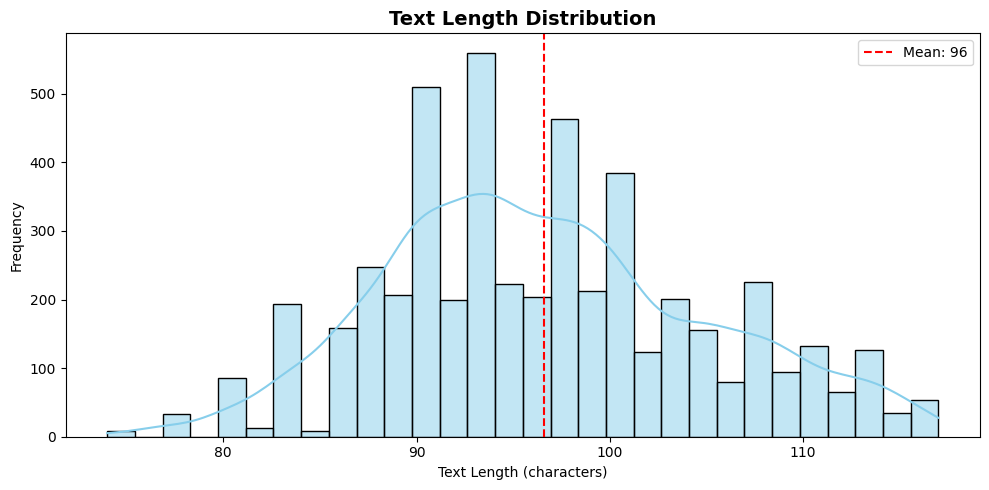

In [39]:
plt.figure(figsize=(10, 5))
sns.histplot(df['text_length'], bins=30, kde=True, color='skyblue')
plt.title('Text Length Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Text Length (characters)')
plt.ylabel('Frequency')
plt.axvline(df['text_length'].mean(), color='red', linestyle='dashed',
            label=f'Mean: {int(df["text_length"].mean())}')
plt.legend()
plt.tight_layout()
plt.show()

##Text Cleaning Function

In [3]:
def clean_text(text):
    if not isinstance(text, str):
        return ""
    text = text.lower()
    text = text.translate(str.maketrans('', '', string.punctuation))
    text = re.sub(r'\d+', '', text)
    return ' '.join(text.split())

df['cleaned_text'] = df['grievance_text'].apply(clean_text)

##Target & Feature Assignment

In [ ]:
X = df['cleaned_text']
y = df['category']

##Label Encoding

In [6]:
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

##Train - Test Split

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

## TF-IDF Vectorization

In [8]:
tfidf_svc = TfidfVectorizer(
    max_features=2500,
    ngram_range=(1, 2),
    stop_words='english',
    min_df=3,
    max_df=0.85,
    sublinear_tf=True
)

In [9]:
tfidf_xgb = TfidfVectorizer(
    max_features=1200,
    ngram_range=(1, 1),
    stop_words='english',
    min_df=10,
    max_df=0.7,
    sublinear_tf=False
)


## Feature Transformation

In [24]:
X_train_svc = tfidf_svc.fit_transform(X_train)
X_test_svc = tfidf_svc.transform(X_test)

X_train_xgb = tfidf_xgb.fit_transform(X_train)
X_test_xgb = tfidf_xgb.transform(X_test)

## Model Training - SVC Model

In [ ]:
svc_model = SVC(
    kernel='rbf',
    C=1.2,
    gamma='scale',
    probability=True,
    random_state=42,
    cache_size=200,
    tol=1e-3
)

print(f"\nTraining SVC...")
svc_model.fit(X_train_svc, y_train)
y_pred_svc = svc_model.predict(X_test_svc)
accuracy_svc = accuracy_score(y_test, y_pred_svc)
print(f" SVC Accuracy: {accuracy_svc:.2%}")
print(f"\nClassification Report (SVC):")
print(classification_report(y_test, y_pred_svc, target_names=label_encoder.classes_))

Training SVC...
 SVC Accuracy: 99.70%

Classification Report (SVC):
              precision    recall  f1-score   support

     Funding       1.00      1.00      1.00       200
      Hiring       0.99      0.99      0.99       200
       Legal       1.00      0.99      1.00       200
   Marketing       1.00      1.00      1.00       200
  Mentorship       0.99      0.99      0.99       200

    accuracy                           1.00      1000
   macro avg       1.00      1.00      1.00      1000
weighted avg       1.00      1.00      1.00      1000


## Model Training -  XGBoost Model

In [12]:
xgb_model = XGBClassifier(
    n_estimators=50,
    max_depth=3,
    learning_rate=0.05,
    random_state=42,
    use_label_encoder=False,
    eval_metric='mlogloss',
    verbosity=0,
    subsample=0.5,
    colsample_bytree=0.5,
    min_child_weight=5,
    reg_alpha=2.0,
    reg_lambda=3.0
)

print(f"\nTraining XGBoost...")
xgb_model.fit(X_train_xgb, y_train)
y_pred_xgb = xgb_model.predict(X_test_xgb)
accuracy_xgb = accuracy_score(y_test, y_pred_xgb)
print(f"✓ XGBoost Accuracy: {accuracy_xgb:.2%}")
print(f"\nClassification Report (XGBoost):")
print(classification_report(y_test, y_pred_xgb, target_names=label_encoder.classes_))



Training XGBoost...
✓ XGBoost Accuracy: 96.20%

Classification Report (XGBoost):
              precision    recall  f1-score   support

     Funding       0.95      0.96      0.96       200
      Hiring       0.91      0.97      0.94       200
       Legal       0.97      0.98      0.97       200
   Marketing       1.00      0.97      0.98       200
  Mentorship       0.99      0.93      0.96       200

    accuracy                           0.96      1000
   macro avg       0.96      0.96      0.96      1000
weighted avg       0.96      0.96      0.96      1000



In [13]:
results = {
    'SVC': {'model': svc_model, 'accuracy': accuracy_svc, 'predictions': y_pred_svc},
    'XGBoost': {'model': xgb_model, 'accuracy': accuracy_xgb, 'predictions': y_pred_xgb}
}


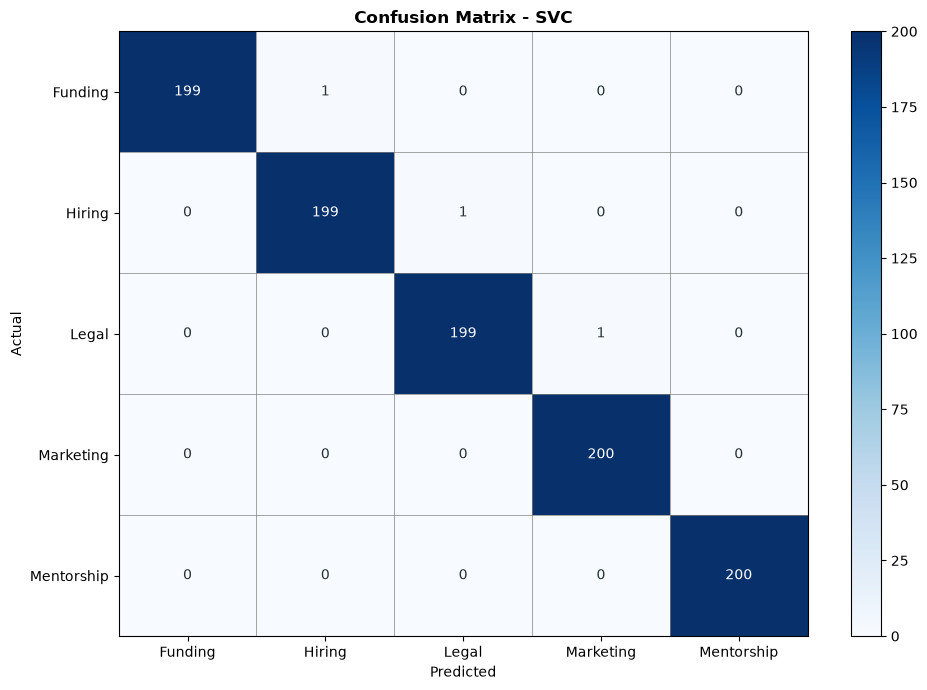

BEST MODEL: SVC
Accuracy: 99.70%


In [ ]:
best_name = max(results, key=lambda x: results[x]['accuracy'])
best_model = results[best_name]['model']
best_predictions = results[best_name]['predictions']

# Chart 4: Confusion Matrix
cm = confusion_matrix(y_test, best_predictions)
plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder.classes_,
            yticklabels=label_encoder.classes_,
            linewidths=0.5, linecolor='black')
plt.title(f'Confusion Matrix - {best_name}', fontsize=14, fontweight='bold')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()


print(f"BEST MODEL: {best_name}")
print(f"Accuracy: {results[best_name]['accuracy']:.2%}")

In [22]:
joblib.dump(best_model, 'best_model.pkl')
joblib.dump(tfidf_svc, 'tfidf_vectorizer.pkl')
joblib.dump(label_encoder, 'label_encoder.pkl')

print("\n Models saved successfully!")
print("    - best_model.pkl")
print("    - tfidf_vectorizer.pkl")
print("    - label_encoder.pkl")


 Models saved successfully!
    - best_model.pkl
    - tfidf_vectorizer.pkl
    - label_encoder.pkl
